# 04 – Baseline cổ điển (BoW / TF-IDF + LR / SVM) với giao thức đánh giá đúng

**Mục tiêu:** tạo *mốc so sánh trung thực* cho bài toán ABSA aspect-category trên SemEval-2016 Res16
trước khi nói đến mô hình sâu. Mọi mô hình về sau (BERT fine-tune, GRU→BiLSTM→Attention…) phải so với bảng này.

**Giao thức (khác notebook 03 gốc):**
1. Validation được tách từ **train**, theo *review* (không để câu cùng review ở cả train và val), stratify theo polarity.
2. Siêu tham số (C) chọn bằng Macro F1 trên **validation**. Tập **test chỉ dùng để báo cáo**.
3. 5 seed (seed đổi cách tách train/val); báo cáo trung bình ± độ lệch chuẩn.
4. Chỉ số chính là **Macro F1** (lớp neutral chỉ chiếm 4,0% ở train và 5,1% ở test), kèm F1 từng lớp. Accuracy chỉ để tham khảo.

In [1]:
import sys, warnings
sys.path.append('../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from absa_common import *

train_df, test_df = load_res16()
print(len(train_df), len(test_df))               # kỳ vọng 2507 / 859
print(train_df.polarity.value_counts().to_dict())
print(test_df.polarity.value_counts().to_dict())
SEEDS = [0, 1, 2, 3, 4]
C_GRID = [0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000]

2507 859
{'positive': 1657, 'negative': 749, 'neutral': 101}
{'positive': 611, 'negative': 204, 'neutral': 44}


## 1. Biểu diễn đặc trưng

Bài toán là *cặp* (câu, khía cạnh). Nếu chỉ dùng TF-IDF của câu thì mô hình **không biết đang hỏi khía cạnh nào**
và sẽ cho cùng một nhãn cho mọi khía cạnh của câu (32% câu có >1 khía cạnh). Ba cách đưa khía cạnh vào mô hình tuyến tính:

| Tên | Đặc trưng | Ý nghĩa |
|---|---|---|
| `S` | TF-IDF(câu) | cận dưới: bỏ qua khía cạnh |
| `S+A` | TF-IDF(câu) ⊕ one-hot(khía cạnh) | khía cạnh chỉ dịch điểm, không đổi *từ nào quan trọng* |
| `S×A` | TF-IDF(câu) ⊕ [TF-IDF(câu) × 1(khía cạnh = a) với mọi a] ⊕ one-hot | mỗi khía cạnh có trọng số từ riêng + phần chung (kiểu "feature augmentation") |

In [2]:
ASPECTS = sorted(train_df.category.unique())
print(len(ASPECTS), ASPECTS)

def aspect_onehot(cats):
    idx = {a: i for i, a in enumerate(ASPECTS)}
    M = sp.lil_matrix((len(cats), len(ASPECTS)))
    for r, c in enumerate(cats):
        M[r, idx[c]] = 1.0
    return M.tocsr()

def cross(X, cats):
    """[X | X*1(a=a1) | ... | X*1(a=aK) | onehot]."""
    A = aspect_onehot(cats)
    blocks = [X] + [sp.diags(A[:, k].toarray().ravel()) @ X for k in range(len(ASPECTS))] + [A]
    return sp.hstack(blocks).tocsr()

def featurize(kind, mode, tr_text, tr_cat, other):
    """Fit vectorizer CHỈ trên train; trả về (X_train, [X_other...])."""
    if kind == 'tfidf':
        vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    else:  # bow nhị phân
        vec = CountVectorizer(lowercase=True, ngram_range=(1, 1), min_df=1, binary=True)
    Xtr = vec.fit_transform(tr_text)
    outs = []
    for text, cat in other:
        X = vec.transform(text)
        outs.append(X)
    def wrap(X, cats):
        if mode == 'S':   return X
        if mode == 'S+A': return sp.hstack([X, aspect_onehot(cats)]).tocsr()
        return cross(X, cats)
    return wrap(Xtr, tr_cat), [wrap(X, c) for X, (_, c) in zip(outs, other)]

12 ['AMBIENCE#GENERAL', 'DRINKS#PRICES', 'DRINKS#QUALITY', 'DRINKS#STYLE_OPTIONS', 'FOOD#PRICES', 'FOOD#QUALITY', 'FOOD#STYLE_OPTIONS', 'LOCATION#GENERAL', 'RESTAURANT#GENERAL', 'RESTAURANT#MISCELLANEOUS', 'RESTAURANT#PRICES', 'SERVICE#GENERAL']


## 2. Chạy thí nghiệm

Mỗi cấu hình × 5 seed. Với mỗi seed: tách train/val → chọn C trên val → đo test (một lần).

In [3]:
CONFIGS = [
    # tên,                         kind,    mode,  model, balanced
    ('TF-IDF  S    · LR',          'tfidf', 'S',   'lr',  False),
    ('TF-IDF  S+A  · LR',          'tfidf', 'S+A', 'lr',  False),
    ('TF-IDF  S+A  · LR (cân bằng lớp)', 'tfidf', 'S+A', 'lr',  True),
    ('TF-IDF  S×A  · LR',          'tfidf', 'S×A', 'lr',  False),
    ('TF-IDF  S×A  · LR (cân bằng lớp)',  'tfidf', 'S×A', 'lr',  True),
    ('TF-IDF  S×A  · LinearSVC (cân bằng lớp)', 'tfidf', 'S×A', 'svm', True),
    ('BoW     S×A  · LR (cân bằng lớp)',  'bow',   'S×A', 'lr',  True),
]

def make_model(name, C, balanced, seed):
    cw = 'balanced' if balanced else None
    if name == 'lr':
        return LogisticRegression(C=C, class_weight=cw, max_iter=2000, random_state=seed)
    return LinearSVC(C=C, class_weight=cw, random_state=seed, max_iter=20000)

results, test_preds = {}, {}
for cname, kind, mode, mname, bal in CONFIGS:
    runs, preds = [], []
    for seed in SEEDS:
        tr_i, va_i = split_train_val(train_df, seed)
        tr, va = train_df.iloc[tr_i], train_df.iloc[va_i]
        Xtr, (Xva, Xte) = featurize(kind, mode, tr.sentence, tr.category,
                                    [(va.sentence, va.category), (test_df.sentence, test_df.category)])
        best = (-1, None)
        for Cv in C_GRID:
            m = make_model(mname, Cv, bal, seed).fit(Xtr, tr.polarity)
            f = metrics(va.polarity, m.predict(Xva))['macro_f1']
            if f > best[0]: best = (f, Cv)
        m = make_model(mname, best[1], bal, seed).fit(Xtr, tr.polarity)   # test chỉ được chạm ở đây
        p = m.predict(Xte)
        r = metrics(test_df.polarity, p); r.update(seed=seed, C=best[1], val_macro_f1=best[0])
        runs.append(r); preds.append(p)
    results[cname] = runs; test_preds[cname] = preds

# mốc "đoán lớp đa số"
maj = ['positive'] * len(test_df)
results['Đoán lớp đa số (positive)'] = [metrics(test_df.polarity, maj)] * len(SEEDS)

tab = pd.DataFrame({k: summarize(v) for k, v in results.items()}).T
tab.columns = ['Accuracy', 'Macro F1', 'F1 negative', 'F1 neutral', 'F1 positive']
tab

,Accuracy,Macro F1,F1 negative,F1 neutral,F1 positive
TF-IDF S · LR,78.18 ± 0.86,55.67 ± 0.73,61.03 ± 1.60,19.19 ± 1.61,86.78 ± 0.63
TF-IDF S+A · LR,80.23 ± 0.82,57.27 ± 0.35,65.76 ± 1.21,17.82 ± 1.86,88.24 ± 0.58
TF-IDF S+A · LR (cân bằng lớp),78.42 ± 1.00,60.51 ± 1.84,65.27 ± 1.79,29.65 ± 5.93,86.61 ± 0.77
TF-IDF S×A · LR,80.35 ± 0.46,55.51 ± 1.36,65.45 ± 1.22,12.86 ± 4.75,88.22 ± 0.34
TF-IDF S×A · LR (cân bằng lớp),78.16 ± 1.59,58.89 ± 2.65,64.40 ± 1.29,25.76 ± 9.77,86.49 ± 1.19
TF-IDF S×A · LinearSVC (cân bằng lớp),81.47 ± 0.70,59.60 ± 1.93,67.71 ± 1.20,22.31 ± 4.37,88.78 ± 0.52
BoW S×A · LR (cân bằng lớp),78.84 ± 1.29,58.67 ± 1.64,63.15 ± 1.26,25.54 ± 3.13,87.33 ± 0.88
Đoán lớp đa số (positive),71.13 ± 0.00,27.71 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,83.13 ± 0.00


## 3. Đọc kết quả

Bảng trên là **trung bình ± độ lệch chuẩn (%) trên 5 seed**, test 859 mẫu. Lưu ý khi so sánh:
- Chênh lệch Accuracy nhỏ hơn ~1 điểm % chỉ tương đương vài câu test và nằm trong dao động giữa các seed → không kết luận được.
- Với lớp neutral (44 mẫu test), mỗi câu đúng/sai làm F1 neutral thay đổi rất nhiều; nên độ lệch chuẩn của F1 neutral lớn.
- Cột Macro F1 mới là chỉ số phản ánh việc mô hình có nhận ra lớp hiếm hay không.

In [4]:
# Chọn C: có ổn định giữa các seed không?
pd.DataFrame({k: pd.Series([r['C'] for r in v]) for k, v in results.items() if 'C' in v[0]}).T.rename(columns=lambda i: f'seed {SEEDS[i]}')

,seed 0,seed 1,seed 2,seed 3,seed 4
TF-IDF S · LR,100.0,100.0,100.0,300.0,100.0
TF-IDF S+A · LR,300.0,100.0,100.0,300.0,30.0
TF-IDF S+A · LR (cân bằng lớp),1000.0,30.0,1.0,1.0,10.0
TF-IDF S×A · LR,1000.0,1000.0,30.0,300.0,300.0
TF-IDF S×A · LR (cân bằng lớp),300.0,0.3,0.3,0.3,1000.0
TF-IDF S×A · LinearSVC (cân bằng lớp),1.0,3.0,0.1,1.0,0.3
BoW S×A · LR (cân bằng lớp),0.1,30.0,30.0,0.3,30.0


## 4. Phân tích lỗi cho cấu hình tốt nhất (theo Macro F1 trung bình)

Cấu hình tốt nhất theo Macro F1: TF-IDF  S+A  · LR (cân bằng lớp)


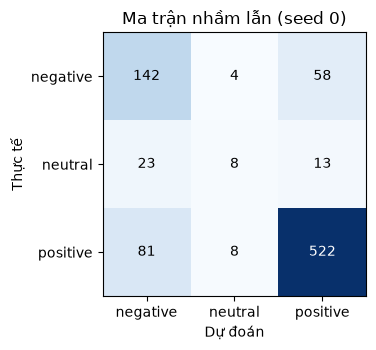

In [5]:
best_name = max((k for k in results if k in test_preds), key=lambda k: np.mean([r['macro_f1'] for r in results[k]]))
print('Cấu hình tốt nhất theo Macro F1:', best_name)
pred = test_preds[best_name][0]          # seed 0
cm = confusion_matrix(test_df.polarity, pred, labels=LABELS)
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(3)); ax.set_xticklabels(LABELS); ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thực tế'); ax.set_title('Ma trận nhầm lẫn (seed 0)')
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max()/2 else 'black')
plt.tight_layout(); plt.show()

In [6]:
# F1 theo từng category và theo target tường minh / ngầm định (seed 0)
d = test_df.copy(); d['pred'] = pred; d['ok'] = d.pred == d.polarity
d['implicit'] = d.target.eq('NULL')
d['n_aspects'] = d.groupby('sid').sid.transform('count')
by_cat = d.groupby('category').apply(lambda g: pd.Series(dict(n=len(g), acc=g.ok.mean()*100,
                      macro_f1=f1_score(g.polarity, g.pred, labels=sorted(set(g.polarity)|set(g.pred)), average='macro', zero_division=0)*100)))
print(by_cat.round(1).to_string())
print()
print('Độ chính xác theo loại target:'); print(d.groupby('implicit').ok.agg(['mean', 'size']).round(3))
print('Độ chính xác theo số khía cạnh của câu:'); print(d.groupby(d.n_aspects.clip(upper=3)).ok.agg(['mean', 'size']).round(3))

                              n   acc  macro_f1
category                                       
AMBIENCE#GENERAL           66.0  83.3      52.4
DRINKS#PRICES               4.0  25.0      20.0
DRINKS#QUALITY             22.0  90.9      32.5
DRINKS#STYLE_OPTIONS       12.0  91.7      47.8
FOOD#PRICES                23.0  78.3      54.5
FOOD#QUALITY              313.0  84.3      54.4
FOOD#STYLE_OPTIONS         55.0  52.7      46.3
LOCATION#GENERAL           13.0  46.2      40.5
RESTAURANT#GENERAL        142.0  80.3      49.4
RESTAURANT#MISCELLANEOUS   33.0  60.6      43.0
RESTAURANT#PRICES          21.0  71.4      49.4
SERVICE#GENERAL           155.0  76.8      52.3

Độ chính xác theo loại target:
           mean  size
implicit             
False     0.800   650
True      0.727   209
Độ chính xác theo số khía cạnh của câu:
            mean  size
n_aspects             
1          0.761   410
2          0.754   256
3          0.865   193


In [7]:
# Các câu neutral bị đoán sai: mô hình đoán gì?
neu = d[d.polarity == 'neutral']
print('Neutral thật:', len(neu), '· đoán đúng:', int((neu.pred == 'neutral').sum()))
print(neu.pred.value_counts().to_dict())
pd.set_option('display.max_colwidth', 110)
neu[neu.pred != 'neutral'][['sentence', 'category', 'pred']].head(8)

Neutral thật: 44 · đoán đúng: 8
{'negative': 23, 'positive': 13, 'neutral': 8}


,sentence,category,pred
2,Not the biggest portions but adequate.,FOOD#STYLE_OPTIONS,negative
150,"The decor is rustic, traditional Japanese.",AMBIENCE#GENERAL,positive
151,"The crowd is mixed yuppies, young and old.",RESTAURANT#MISCELLANEOUS,positive
154,The outside patio area has an abbreviated menu.,FOOD#STYLE_OPTIONS,positive
159,Service was decent.,SERVICE#GENERAL,negative
185,– tucked away over by the Beverly Center.,LOCATION#GENERAL,positive
313,"It was so much though that I could barely finish but I did, since it was delicious.",FOOD#STYLE_OPTIONS,negative
357,"On weekends, you might have to wait for couple hours.",SERVICE#GENERAL,positive


## 5. Kết luận

**Tóm tắt (test 859 mẫu, trung bình ± độ lệch chuẩn qua 5 seed):**
1. Thông tin khía cạnh có ích: S → S+A tăng Accuracy +2,05 và Macro F1 +1,60. Biểu diễn tương tác **S×A** không hơn S+A.
2. **Class weight** là thay đổi có tác động mạnh nhất: Macro F1 tăng khoảng 3,2–3,4 điểm, F1 neutral tăng khoảng 12–13 điểm.
3. **Mốc cần vượt cho mô hình sâu: Macro F1 ≈ 59–61%.** Mạnh nhất theo trung bình là S+A cân bằng lớp (60,51 ± 1,84); các cấu hình cân bằng lớp còn lại đạt 58,7–59,6, cùng nằm trong khoảng nhiễu.

Lưu ý chung: độ lệch chuẩn ở đây chỉ phản ánh cách tách train/validation, còn tập test cố định (neutral chỉ 44 mẫu). Chênh lệch dưới ~2 điểm giữa các cấu hình không đủ để kết luận.

### 1. Khía cạnh có thực sự giúp ích không (S, S+A, S×A)?

Chỉ so ba cấu hình **không cân bằng lớp** (TF-IDF + LR):

| Cấu hình | Accuracy | Macro F1 | F1 neg | F1 neutral | F1 pos |
|---|---:|---:|---:|---:|---:|
| S | 78,18 | 55,67 | 61,03 | 19,19 | 86,78 |
| S+A | 80,23 | **57,27** | 65,76 | 17,82 | 88,24 |
| S×A | **80,35** | 55,51 | 65,45 | 12,86 | 88,22 |

- **S → S+A:** Accuracy +2,05, Macro F1 +1,60. Phần tăng đến từ F1 negative (+4,73) và positive (+1,46). F1 neutral gần như không đổi (19,19 → 17,82): biết khía cạnh không giúp nhận ra lớp neutral.
- **S×A:** Macro F1 (55,51) ngang S (−0,16) và thấp hơn S+A 1,76 điểm; F1 neutral thấp nhất trong ba cấu hình (12,86). Accuracy chỉ ngang S+A (+0,12). Vậy S×A không tốt hơn S+A. Lý do có thể là S×A có nhiều tham số hơn nhiều trên chỉ 2 507 mẫu (đây là giả thuyết, chưa kiểm chứng).
- **Chọn C khá nhiễu.** Lưới C đã mở đến 1000, nhưng vẫn có 4/35 lần chọn rơi đúng mép 1000, và C được chọn dao động rất rộng giữa các seed (S×A cân bằng lớp: 0,3 đến 1000). Khi mở lưới từ 100 lên 1000, Macro F1 của S×A cân bằng lớp đổi từ 60,57 xuống 58,89. Tập validation chỉ khoảng 356 mẫu với cỡ 15 mẫu neutral, nên việc chọn C trên đó không ổn định. Vì vậy không diễn giải chênh lệch nhỏ hơn ~2 điểm giữa các cấu hình LR.

### 2. Class weight cải thiện F1 neutral bao nhiêu, đánh đổi gì?

Cùng một mô hình, chỉ bật cân bằng lớp (số trong ngoặc là thay đổi):

| Chỉ số | S+A: không → cân bằng | S×A: không → cân bằng |
|---|---:|---:|
| Accuracy | 80,23 → 78,42 (−1,81) | 80,35 → 78,16 (−2,19) |
| Macro F1 | 57,27 → **60,51** (+3,24) | 55,51 → **58,89** (+3,38) |
| F1 negative | 65,76 → 65,27 (−0,49) | 65,45 → 64,40 (−1,05) |
| F1 neutral | 17,82 → **29,65** (+11,83) | 12,86 → **25,76** (+12,90) |
| F1 positive | 88,24 → 86,61 (−1,63) | 88,22 → 86,49 (−1,73) |

- Cân bằng lớp kéo F1 neutral lên khoảng 26–30, đổi lại Accuracy giảm 1,8–2,2 điểm và F1 positive giảm 1,6–1,7 điểm. Nếu mục tiêu là Macro F1 thì đây là đánh đổi có lợi, và hướng này nhất quán ở cả hai cấu hình.
- F1 neutral vẫn rất thấp và dao động mạnh (S×A cân bằng lớp: 25,76 ± 9,77): neutral vẫn là điểm yếu chính.
- LinearSVC cân bằng lớp có Accuracy cao nhất bảng (81,47) và Macro F1 59,60 ± 1,93, nằm giữa S+A và S×A cân bằng lớp. Chọn mô hình nào phụ thuộc chỉ số ưu tiên.
- BoW nhị phân S×A (58,67) gần như bằng TF-IDF S×A (58,89; chênh 0,22), nên n-gram TF-IDF không cho lợi thế rõ ở đây.

### 3. Mốc Macro F1 cần vượt, và lỗi nằm ở đâu?

**Mốc:** Macro F1 ≈ **59–61%**. Theo trung bình, S+A cân bằng lớp mạnh nhất (60,51 ± 1,84), sau đó là LinearSVC cân bằng lớp (59,60 ± 1,93), S×A cân bằng lớp (58,89 ± 2,65) và BoW (58,67 ± 1,64). Bốn cấu hình chênh nhau dưới ~2 điểm, cỡ độ lệch chuẩn, nên coi là một nhóm ngang nhau. Mốc thấp để tham chiếu: luôn đoán positive cho Accuracy 71,13 nhưng Macro F1 chỉ 27,71; vì thế Accuracy một mình không đủ để đánh giá bài toán này. Mô hình sâu chỉ có ý nghĩa nếu vượt mốc này qua nhiều seed, không phải chỉ một lần chạy.

**Phân tích lỗi** (S+A cân bằng lớp, seed 0, test; đây là một seed nên chỉ mang tính minh họa):
- **Target ngầm khó hơn:** Accuracy 72,7% (209 mẫu) so với 80,0% (650 mẫu) ở target tường minh, chênh 7,3 điểm.
- **Số khía cạnh của câu:** 1 khía cạnh 76,1%; 2 khía cạnh 75,4%; từ 3 khía cạnh 86,5%. Chưa rõ vì sao nhóm nhiều khía cạnh dễ hơn nên không rút kết luận.
- **Theo category:** FOOD#QUALITY (313 mẫu) đạt 84,3%; FOOD#STYLE_OPTIONS (55 mẫu) chỉ 52,7%, thấp nhất trong các nhóm đủ lớn. Các nhóm nhỏ như DRINKS#PRICES (4 mẫu, 25,0%) và LOCATION#GENERAL (13 mẫu, 46,2%) không đủ để kết luận. Macro F1 theo category tính trên các nhãn có mặt trong nhóm, nên thấp ngay cả khi Accuracy cao (DRINKS#QUALITY: Accuracy 90,9%, Macro F1 32,5) vì neutral rất hiếm.
- **Lớp neutral:** có 44 mẫu thật, chỉ đoán đúng 8; 23 mẫu bị đoán là negative và 13 là positive. Các mẫu sai đều có nhãn thật là neutral, ví dụ "Service was decent." (đoán negative), "The decor is rustic, traditional Japanese." (đoán positive), "– tucked away over by the Beverly Center." (đoán positive). Nhiều câu neutral là mô tả trung tính hoặc ý kiến nhẹ, ranh giới với positive/negative mơ hồ. Đây là nhận xét từ vài ví dụ, chưa kiểm chứng trên toàn bộ.

**Kết luận chung:** thông tin khía cạnh và cân bằng lớp đều có ích nhưng theo hai cách khác nhau. S+A tăng Accuracy và Macro F1 (chủ yếu ở lớp negative). Class weight là thay đổi mạnh nhất vì kéo F1 neutral từ 13–18% lên khoảng 26–30%, đổi lại mất 1,8–2,2 điểm Accuracy. Baseline cổ điển mạnh nhất đạt Macro F1 ≈ 59–61% (S+A cân bằng lớp 60,51 ± 1,84) và neutral vẫn là điểm yếu. Việc chọn C trên validation nhỏ khá nhiễu, nên chênh lệch dưới ~2 điểm giữa các cấu hình không đáng tin. Đây là mốc để so sánh với các mô hình sâu ở notebook 05.